In [53]:
import matplotlib.pyplot as plt

from lib.target_definition import Target
from lib.target_utils import query_data
import lib.mcmc_utils as mcmc
import emcee
import numpy as np
from scipy.stats import norm
import os


%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Prepare data


### You may run a test using mock data generated from PARSEC V2.0 isochrones

In [ ]:
# # Mock pre-MS star A
target_name =      'Mock pre-MS star B'
cluster =          ''
true_values =      np.array([2.634866, 6.477120   , 0.01 , 0.8 , 0.524, 100]) # True values [Mass, logAge, MH, omega, Inclination, parallax]

obs_mags =         np.array([0.249000, 0.277000, 0.195000, 0.325, 0.294, 0.119, 0.129, 0.109]) # Noise with uncertainty=0.01 is injected into Gaia bands
obs_err_mags =     np.array([0.002,  0.002,  0.002,   0.02,    0.02,    0.02,   0.02,    0.02 ])
obs_mags = obs_mags + np.random.normal(loc=0.0, scale=[0.02]*8)

vsini_obs =        4
vsini_obs_err =    4
parallax_obs =     100
parallax_obs_err = 0.03
extinction =       0.0
extinction_err =   0.001
extinction_type =  'A_V'

In [ ]:
# # Mock SGB star A
target_name =      'Mock SGB star A'
cluster =          ''
true_values =      np.array([2.0901, 9.   , 0.01 , 0.8 , 0.524, 100]) # True values [Mass, logAge, MH, omega, Inclination, parallax]

obs_mags =         np.array([0.487,	0.613,	0.26,	0.827,	0.59,	0.025,	-0.059,	-0.089]) # Noise with uncertainty=0.01 is injected into Gaia bands
obs_err_mags =     np.array([0.002,  0.002,  0.002,   0.02,    0.02,    0.02,   0.02,    0.02 ])
obs_mags = obs_mags + np.random.normal(loc=0.0, scale=[0.02]*8)

vsini_obs =        75.5
vsini_obs_err =    5
parallax_obs =     100
parallax_obs_err = 0.03
extinction =       0.0
extinction_err =   0.001
extinction_type =  'A_V'

In [ ]:
# # Mock SGB star A
target_name =      'Mock boundary star A'
cluster =          ''
true_values =      np.array([2.20108,8.88081,0.01,0.8,0.524, 100]) # True values [Mass, logAge, MH, omega, Inclination, parallax]

obs_mags =         np.array([0.567,0.646,0.418,0.784,0.639,0.254,0.215,0.19]) # Noise with uncertainty=0.01 is injected into Gaia bands
obs_err_mags =     np.array([0.002,  0.002,  0.002,   0.02,    0.02,    0.02,   0.02,    0.02 ])
obs_mags = obs_mags + np.random.normal(loc=0.0, scale=[0.02]*8)

vsini_obs =        83
vsini_obs_err =    5
parallax_obs =     100
parallax_obs_err = 0.03
extinction =       0.0
extinction_err =   0.001
extinction_type =  'A_V'

In [ ]:
# # Mock SGB star A
target_name =      'Mock boundary star A (under the missed triangle region)'
cluster =          ''
true_values =      np.array([2.342526,8.8488,0.01,0.8,0.524, 100]) # True values [Mass, logAge, MH, omega, Inclination, parallax]

obs_mags =         np.array([0.198,0.272,0.058,0.398,0.267,-0.101,-0.136,-0.162]) # Noise with uncertainty=0.01 is injected into Gaia bands
obs_err_mags =     np.array([0.002,  0.002,  0.002,   0.02,    0.02,    0.02,   0.02,    0.02 ])
obs_mags = obs_mags + np.random.normal(loc=0.0, scale=[0.02]*8)

vsini_obs =        76
vsini_obs_err =    5
parallax_obs =     100
parallax_obs_err = 0.03
extinction =       0.0
extinction_err =   0.001
extinction_type =  'A_V'

In [ ]:
target_name =      'Mock star B'
cluster =          ''
true_values = np.array([3.04128,8.25527,0.01,0.8,0.524, 10])
# current Mass, omega: 3.04,0.7829
obs_mags = np.array([5.09989, 5.05902, 5.17989, 5.00064, 5.13055, 5.27743, 5.34131, 5.35378])
obs_err_mags = np.array([0.002,  0.002,  0.002,   0.02,    0.02,    0.02,   0.02,    0.02 ])
obs_mags = obs_mags + np.random.normal(loc=0.0, scale=[0.02]*8)

vsini_obs =        119
vsini_obs_err =    5
parallax_obs =     10
parallax_obs_err = 0.03
extinction =       0.01
extinction_err =   0.001
extinction_type =  'A_V'

In [ ]:
M_obs = np.array([1.287, 1.355, 1.159, 1.483, 1.352, 1.021, 0.997, 0.974])
# vsini = 82.71412442355152
from lib.target_utils import cal_obs_mag
np.round(cal_obs_mag(M_obs, 18.3851), 3)

In [ ]:
target_name =      'Mock Hyades star (2 Msun)'
cluster =          ''
true_values = np.array([2, np.log10(700)+6, 0.09, 0.8, np.deg2rad(30), 10])
# current Mass, omega: 2.049,0.751
obs_mags = np.array([4.965, 5.033, 4.837, 5.161, 5.03 , 4.699, 4.675, 4.652])
obs_err_mags = np.array([0.002,  0.002,  0.002,   0.02,    0.02,    0.02,   0.02,    0.02 ])
obs_mags = obs_mags + np.random.normal(loc=0.0, scale=[0.02]*8)

vsini_obs =        88
vsini_obs_err =    5
parallax_obs =     18.3851
parallax_obs_err = 0.1772
extinction =       0.01
extinction_err =   0.001
extinction_type =  'A_V'

In [ ]:
target_name =      'Mock Hyades star (2.25 Msun)'
cluster =          ''
true_values = np.array([2.25, np.log10(700)+6, 0.09, 0.8, np.deg2rad(30), 10])
# current Mass, omega: 2.049,0.751
obs_mags = np.array([4.255, 4.32 , 4.134, 4.435, 4.319, 3.996, 3.972, 3.948])
obs_err_mags = np.array([0.002,  0.002,  0.002,   0.02,    0.02,    0.02,   0.02,    0.02 ])
obs_mags = obs_mags + np.random.normal(loc=0.0, scale=[0.02]*8)

vsini_obs =        86
vsini_obs_err =    5
parallax_obs =     18.3851
parallax_obs_err = 0.1772
extinction =       0.01
extinction_err =   0.001
extinction_type =  'A_V'

In [ ]:
target_name =      'Mock star A (omega_ini=0.3, 30 deg)'
cluster =          ''
true_values = np.array([2.05,8.25527,0.01,0.3,np.deg2rad(60), 10])
# current Mass, omega: 2.049,0.751
obs_mags = np.array([6.614427,6.623118,6.60017,6.652187,6.648803,6.573414,6.604288,6.589536])
obs_err_mags = np.array([0.002,  0.002,  0.002,   0.02,    0.02,    0.02,   0.02,    0.02 ])
obs_mags = obs_mags + np.random.normal(loc=0.0, scale=[0.02]*8)

vsini_obs =        64
vsini_obs_err =    5
parallax_obs =     10
parallax_obs_err = 0.03
extinction =       0.01
extinction_err =   0.001
extinction_type =  'A_V'

In [ ]:
target_name =      'Mock star A (30 deg)'
cluster =          ''
true_values = np.array([2.05,8.25527,0.01,0.8,0.524, 10])
# current Mass, omega: 2.049,0.751
obs_mags = np.array([6.49789, 6.51402, 6.46989, 6.55864, 6.53655, 6.42643, 6.45031, 6.43378])
obs_err_mags = np.array([0.002,  0.002,  0.002,   0.02,    0.02,    0.02,   0.02,    0.02 ])
obs_mags = obs_mags + np.random.normal(loc=0.0, scale=[0.02]*8)

vsini_obs =        110
vsini_obs_err =    5
parallax_obs =     10
parallax_obs_err = 0.03
extinction =       0.01
extinction_err =   0.001
extinction_type =  'A_V'


In [ ]:
target_name =      'Mock star A (0 deg)'
cluster =          ''
true_values = np.array([2.05,8.25527,0.01,0.8,0.0, 10])
obs_mags = np.array([6.434,6.446,6.415,6.481,6.47,6.381,6.409,6.393])
obs_err_mags = np.array([0.002,  0.002,  0.002,   0.02,    0.02,    0.02,   0.02,    0.02 ])
obs_mags = obs_mags + np.random.normal(loc=0.0, scale=[0.02]*8)

vsini_obs =        0
vsini_obs_err =    5
parallax_obs =     10
parallax_obs_err = 0.03
extinction =       0.01
extinction_err =   0.001
extinction_type =  'A_V'


In [ ]:

target_name =      'Mock star A (90 deg)'
cluster =          ''
true_values = np.array([2.05,8.25527,0.01,0.8,1.57, 10])
# current Mass, omega: 2.049,0.751
obs_mags = np.array([6.673979,6.701977,6.621982,6.766973,6.716978,6.558985,6.574986,6.555986])
obs_err_mags = np.array([0.002,  0.002,  0.002,   0.02,    0.02,    0.02,   0.02,    0.02 ])
obs_mags = obs_mags + np.random.normal(loc=0.0, scale=[0.02]*8)

vsini_obs =        110/np.sin(0.524)
vsini_obs_err =    5
parallax_obs =     10
parallax_obs_err = 0.03
extinction =       0.01
extinction_err =   0.001
extinction_type =  'A_V'


In [ ]:
target_name =      'Mock star F'
cluster =          ''
true_values = np.array([1.5,8.86923,0.01,0.8,0.524, 10])
# current Mass, omega: 1.5,0.7543
obs_mags = np.array([7.62589, 7.79602, 7.32789, 8.09164, 7.76555, 7.04543, 6.92231, 6.88778])
obs_err_mags = np.array([0.002,  0.002,  0.002,   0.02,    0.02,    0.02,   0.02,    0.02 ])
obs_mags = obs_mags + np.random.normal(loc=0.0, scale=[0.02]*8)

vsini_obs =        99
vsini_obs_err =    5
parallax_obs =     10
parallax_obs_err = 0.03
extinction =       0.01
extinction_err =   0.001
extinction_type =  'A_V'

In [37]:
target_name =      'Mock star A (near TAMS)'
cluster =          ''
true_values = np.array([2, np.log10(900)+6, 0, 0.8, 0.524, 10])
# current Mass, omega: 2.049,0.751
obs_mags = np.array([6.0597185 , 6.15771397, 5.87852749, 6.32970703, 6.14421348, 5.68973702, 5.6345415 , 5.6085451 ])
obs_err_mags = np.array([0.002,  0.002,  0.002,   0.02,    0.02,    0.02,   0.02,    0.02 ])
obs_mags = obs_mags + np.random.normal(loc=0.0, scale=[0.02]*8)

vsini_obs =        73
vsini_obs_err =    5
parallax_obs =     10
parallax_obs_err = 0.03
extinction =       0.00
extinction_err =   0.001
extinction_type =  'A_V'

In [45]:
target_name =      'Mock star F (near TAMS)'
cluster =          ''
true_values = np.array([1.7, np.log10(1000)+6, -0.7, 0.8, 0.524, 10])
# current Mass, omega: 2.049,0.751
obs_mags = np.array([[6.39564342, 6.41897445, 6.35007045, 6.46470548, 6.43886899, 6.28006102, 6.29319361, 6.27539361]])
obs_err_mags = np.array([0.002,  0.002,  0.002,   0.02,    0.02,    0.02,   0.02,    0.02 ])
obs_mags = obs_mags + np.random.normal(loc=0.0, scale=[0.02]*8)

vsini_obs =        101
vsini_obs_err =    5
parallax_obs =     10
parallax_obs_err = 0.03
extinction =       0.00
extinction_err =   0.001
extinction_type =  'A_V'

### Alternatively, you may also query necessary data from databases.

In [ ]:
cluster = 'Pleiades'
target_name = 'HD 23872'

In [ ]:
cluster = 'Praesepe'
# target_name = 'HIP 42578'
target_name = 'HIP 42485'
# target_name = 'HD 73711'
# target_name = 'HD 73449'

In [ ]:
cluster = 'Pleiades'
target_name = 'HIP 17579'

In [ ]:
cluster = ''
target_name = 'kappa Andromedae'
extinction = 0.029

In [ ]:
cluster = 'Hyades'
# target_name = 'HIP 23497'
target_name = 'HIP 20635'
# target_name = 'HIP 21036'

In [ ]:
cluster = ''
target_name = 'HIP 54515'

In [54]:
cluster = ''
# target_name = 'HIP 8847'
target_name = 'HIP 46065'

In [ ]:
cluster = 'Pleiades'
target_name = 'HIP 17527'

In [ ]:
cluster = ''
target_name = 'HIP 84122'

In [ ]:
# target_name = 'HD 67710'

In [55]:
target_name = target_name.strip()
obs_mags, obs_err_mags, vsini_obs, vsini_obs_err, parallax_obs, parallax_obs_err,\
    EBP_RP_obs, EBP_RP_obs_lower, EBP_RP_obs_upper, additional_info = query_data(target_name,  return_df=False)

Target : HIP 46065
IDs    : Gaia DR3 5630038471012148352 | HIP 46065 | HD 81254 | 2MASS J09233953-3312016
------------------------------------------------------------------------------------------------------------------------
RA            : 140.9147           | G        :   6.7175 ±   0.0002 mag            | B_T :   6.8690 ±   0.0140 mag           
Dec           : -33.2005           | G_BP     :   6.7551 ±   0.0005 mag            | V_T :   6.7370 ±   0.0100 mag           
Spectral Type : A3V                | G_RP     :   6.6200 ±   0.0004 mag            | -------------------------               
Object Type   : *                  | Parallax :  11.0497 ±   0.0222 mas            | J   :   6.5030 ±   0.0240 mag           
Distance      : 90.50 ± 0.18 pc    | RUWE     :   0.8620                           | H   :   6.5110 ±   0.0330 mag           
                                   | Vbroad   : 180.2245 ±     4.53 km/s           | Ks  :   6.4780 ±   0.0240 mag           
                 

In [ ]:
# vsini_obs, vsini_obs_err = 176, 17.6 # kappa Andromedae
# vsini_obs, vsini_obs_err = 94, 9.4 # HIP 20635

In [56]:
# The exticntion/redenening should be set carefully.
# Adopting a slightly larger extinction uncertainty is recommended in order to mitigate the risk of underestimating extinction.

# extinction = 0.019 # HIP 20635
# extinction = 0.022 # HIP 23497
# extinction = 0.031 # HIP 42993
# extinction = 0.033 # HIP 42766
# extinction = 0.147 # HIP 17579
# extinction = 0.182 # HD 23872
# extinction = 0.033 # HIP 42578
# extinction = 0.032 # HIP 42485
# extinction = 0.032 # HD 73711
# extinction = 0.033 # HD 73449
# extinction = 0.022 # HIP 54515
# extinction = 0.029 # HIP 8847
extinction = 0.028 # HIP 46065
# extinction = 0.148 # HIP 17527
# extinction = 0.056 # HIP 84122


extinction_err = 0.001
# extinction_type='EB_V' #' A_V' or 'EB_V', or 'EBP_RP'
extinction_type='A_V'

# Set Target

In [57]:
target = Target(name = target_name,
                bands_list = ['G', 'G_BP', 'G_RP', 'B_T', 'V_T', 'J', 'H', 'Ks'],
                obs_mags = obs_mags,
                obs_err_mags = obs_err_mags,
                vsini_obs = vsini_obs,
                vsini_obs_err = vsini_obs_err,
                parallax_obs = parallax_obs,
                parallax_obs_err = parallax_obs_err,
                sigma_adjustment_parameter = 1,
                extinction_parameter = True,
                true_values=False,
                )

In [58]:
target.add_info(cluster=cluster,
                sampling_variables_list = ['Mini', 'logAge', 'MH', 'omega_ini', 'Inclination', 'parallax'],
                extinction=extinction,
                extinction_err=extinction_err,
                extinction_type=extinction_type
)
target.known_parameter(true_values=np.full(6, None))
# target.known_parameter(true_values=true_values)


In [ ]:
# if you want to sample with fixed metallicity [M/H] = 0.0, please give the value by target.known_parameter()

target.add_info(cluster=cluster,
                sampling_variables_list = ['Mini', 'logAge', 'omega_ini', 'Inclination', 'parallax'], # not sampling MH
                extinction=extinction,
                extinction_err=extinction_err,
                extinction_type=extinction_type
)
target.known_parameter(known_MH=0) # giving fixed MH here


In [ ]:
target.add_info(cluster=cluster,
                sampling_variables_list = ['Mini', 'logAge', 'MH', 'parallax'],
                extinction=extinction,
                extinction_err=extinction_err,
                extinction_type=extinction_type
)
target.known_parameter(known_omega_ini=1e-8, known_Inclination=1e-8)

# Set method

In [59]:
# METHOD DIRECT

# using regular PARSEC v2.0 isochrones. For regularization, please see preparation_tutorial.ipynb

target.set_method(
    grids_path='./data/isochrones/regular_Mini_grids/regularized_Mini_grid_1e6_2000e6yr_step10e6_linear_isochrones_preMS&MS_with_inc.npz',
    grids_type='Mini',
    METHOD='DIRECT',
)


Loaded regularized Mini grid.
grid_type: with_inc
interp_variable_list: ['Mini', 'logAge', 'MH', 'omega_ini', 'Inclination']
interp_output_list: ['Mass', 'omega', 'Req', 'Rpol', 'G', 'G_BP', 'G_RP', 'B_T', 'V_T', 'J', 'H', 'Ks']
grid_outputs shape: (1392, 201, 12, 7, 11, 12)
grid_bounds shape: (201, 12, 7, 11, 2)
grid_outputs dtype: float32
grid_bounds dtype: float32
save_float32: True
read_all_at_once: True
total grid memory: 11835.89 MB (11.56 GB)


In [48]:
# METHOD DIRECT

# using regular PARSEC v2.0 isochrones. For regularization, please see preparation_tutorial.ipynb

target.set_method(
    grids_path='./data/isochrones/regular_u_grids/regularized_u_grid_1e6_2000e6yr_step10e6_linear_isochrones_MS_with_inc.npz',
    grids_type='u',
    METHOD='DIRECT',
)

Loaded u-regularized grid.
grid_type: with_inc
interp_variable_list: ['Mini', 'logAge', 'MH', 'omega_ini', 'Inclination']
interp_variable_list_regular: ['u', 'logAge', 'MH', 'omega_ini', 'Inclination']
interp_output_list: ['Mass', 'omega', 'Req', 'Rpol', 'G', 'G_BP', 'G_RP', 'B_T', 'V_T', 'J', 'H', 'Ks']
u_grid shape: (1392,)
grid_outputs shape: (1392, 201, 12, 7, 11, 12)
grid_bounds shape: (201, 12, 7, 11, 2)
grid_outputs dtype: float32
grid_bounds dtype: float32
read_all_at_once: True
save_float32: True
u_save_range: [0.0, 1.0]
u_grid_was_cropped: False
n_u_original: 1392
n_u_saved: 1392
total grid memory: 11835.89 MB (11.56 GB)


In [ ]:
target.set_method(
    grids_path='./regular_Mini_grids/regularized_Mini_grid_1e6_100e6yr_step1e6_&_100e6_1000e6yr_step10e6_linear_isochrones_preMS&MS_with_inc.npz',
    grids_type='Mini',
    METHOD='DIRECT',
)


In [ ]:
# # METHOD PARS

# # Using the PARS package to calculate the temperature distribution over the stellar surface
# # and integrate the visible part to derive apparent magnitudes.

target.set_method(
    grids_path='./data/isochrones/regular_Mini_grids/regularized_Mini_grid_1e6_2000e6yr_step10e6_linear_isochrones_preMS&MS_without_inc.npz',
    grids_type='Mini',
    METHOD='PARS',
    PARS_limb_darkening_path='./data/Kurucz_limb_darkening/i[pm]*k*.pck*',
    PARS_filters='./data/PARS_filters/*.dat',
)

In [ ]:
[list(target.made_limb_darkening_dict.values())[0].bands.index(band) for band in target.bands_list]

In [ ]:
target.bands_list

In [ ]:
# # METHOD PARS

# # Using the PARS package to calculate the temperature distribution over the stellar surface
# # and integrate the visible part to derive apparent magnitudes.

target.set_method(
    grids_path='./regular_u_grids/regularized_u_grid_1e6_2000e6yr_step10e6_linear_isochrones_MS_without_inc.npz',
    grids_type='u',
    METHOD='PARS',
    PARS_limb_darkening_path='./data/Kurucz_limb_darkening/i[pm]*k*.pck*',
    PARS_filters='./data/PARS_filters/*.dat',
)

In [ ]:
target.set_method(
    grids_path='./data/isochrones/regular_grids_MIST/regularized_MIST_Mini_grid.npz',
    grids_type='Mini',
    iso_name='MIST',
    METHOD='PARS',
    PARS_limb_darkening_path='./data/Kurucz_limb_darkening/i[pm]*k*.pck*',
    PARS_filters='./data/PARS_filters/*.dat',
)

# Sampling

In [66]:
target.interp_lower_limit[1] = np.log10(10)+6
# target.interp_lower_limit[1] = 6

In [67]:
import numpy as np


def logp_MH(x, mu=-0.02-0.018, sigma_plus=0.14, sigma_minus=0.12):
# -0.018 to convert MH zeropoint from Asplund to PARSEC v2.0

    if x > mu:
        sigma = sigma_plus
    else:
        sigma = sigma_minus
    return -0.5 * ((x - mu) / sigma)**2

In [68]:
# Set initial states and prior distributions for sampling.

target.set_sampling(nwalkers=30,
                    # mini_prior = lambda x: norm.logpdf(x, loc=2.35, scale=0.01),
                    # logAge_prior = lambda x: norm.logpdf(x, loc=8.99, scale=0.01),
                    # logAge_prior = lambda x: 0,
                    MH_prior=logp_MH,
                    # MH_prior = lambda x: norm.logpdf(x, loc=-0.7, scale=0.05),
                    # MH_prior = lambda x: norm.logpdf(x, loc=0.09, scale=0.07),
                    # MH_prior = lambda x: norm.logpdf(x, loc=0.14, scale=0.08),
                    # inclination_prior = lambda x: norm.logpdf(x, loc=np.deg2rad(30), scale=np.deg2rad(6)),
                    extinction_prior = lambda x: norm.logpdf(x, loc=extinction, scale=extinction_err),
                    )

Sampling parameter space:
Parameter           Min        Max
----------------------------------
Mini             0.0900    14.0000
logAge           7.0000     9.3010
MH              -0.7900     0.3100
omega_ini        0.0000     0.9900
Inclination      0.0000     1.5708
parallax         6.0497    16.0497
sigma            0.0000     0.1000
extinction       0.0000     1.0000


In [51]:
# target.Vrot_prior = lambda x: 0
mcmc.target = target
# mcmc.log_posterior([1.75, np.log10(330)+6, 0.01, 0.6, 0.3, target.parallax_obs] + [0.01, 0.03])
mcmc.log_posterior(target.true_values.tolist() + [0.02, 0.001])
# mcmc.log_posterior([2.00, np.log10(824)+6, 0.03, 0.83, 0.527, 5] + [0.02, 0.001])
# mcmc.log_likelihood_PARS([2.00, np.log10(180)+6, 0.01, 0.0, 1.5,  target.parallax_obs] + [0.02, 0.01], verbose=True)

(np.float64(22.47802873991383),
 array([  6.39669536,   6.42020829,   6.35087372,   6.46633201,
          6.44006968,   6.28047623,   6.29347255,   6.27561965,
        100.9063498 ,  10.        ,  11.4697737 , 201.67256529,
          1.69667881,   0.77952021,   2.06459677,   1.82788568,
         -5.73488685,  23.81350343,   0.91302322]))

In [ ]:
target.Model_interp([2.0, np.log10(180)+6, 0.01, 0.2])

Estimating rough mass...


100%|██████████| 3000/3000 [00:22<00:00, 134.20it/s]

====> Using default Vrot prior: 1.70-2.10 Msun
Running a test with 3000 samples...



100%|██████████| 3000/3000 [00:23<00:00, 129.10it/s]


acceptance ratio:
	0.22 0.25 0.24 0.23 0.26 0.25 0.24 0.20 0.24 
	0.26 0.23 0.23 0.24 0.24 0.25 0.10 0.24 0.26 
	0.24 0.23 0.23 0.24 0.25 0.26 0.24 0.27 0.24 
	0.26 0.26 0.23 
nsteps/60: 50.00
autocorrelation time: [ 48 184 108 121 275  34 143  43]


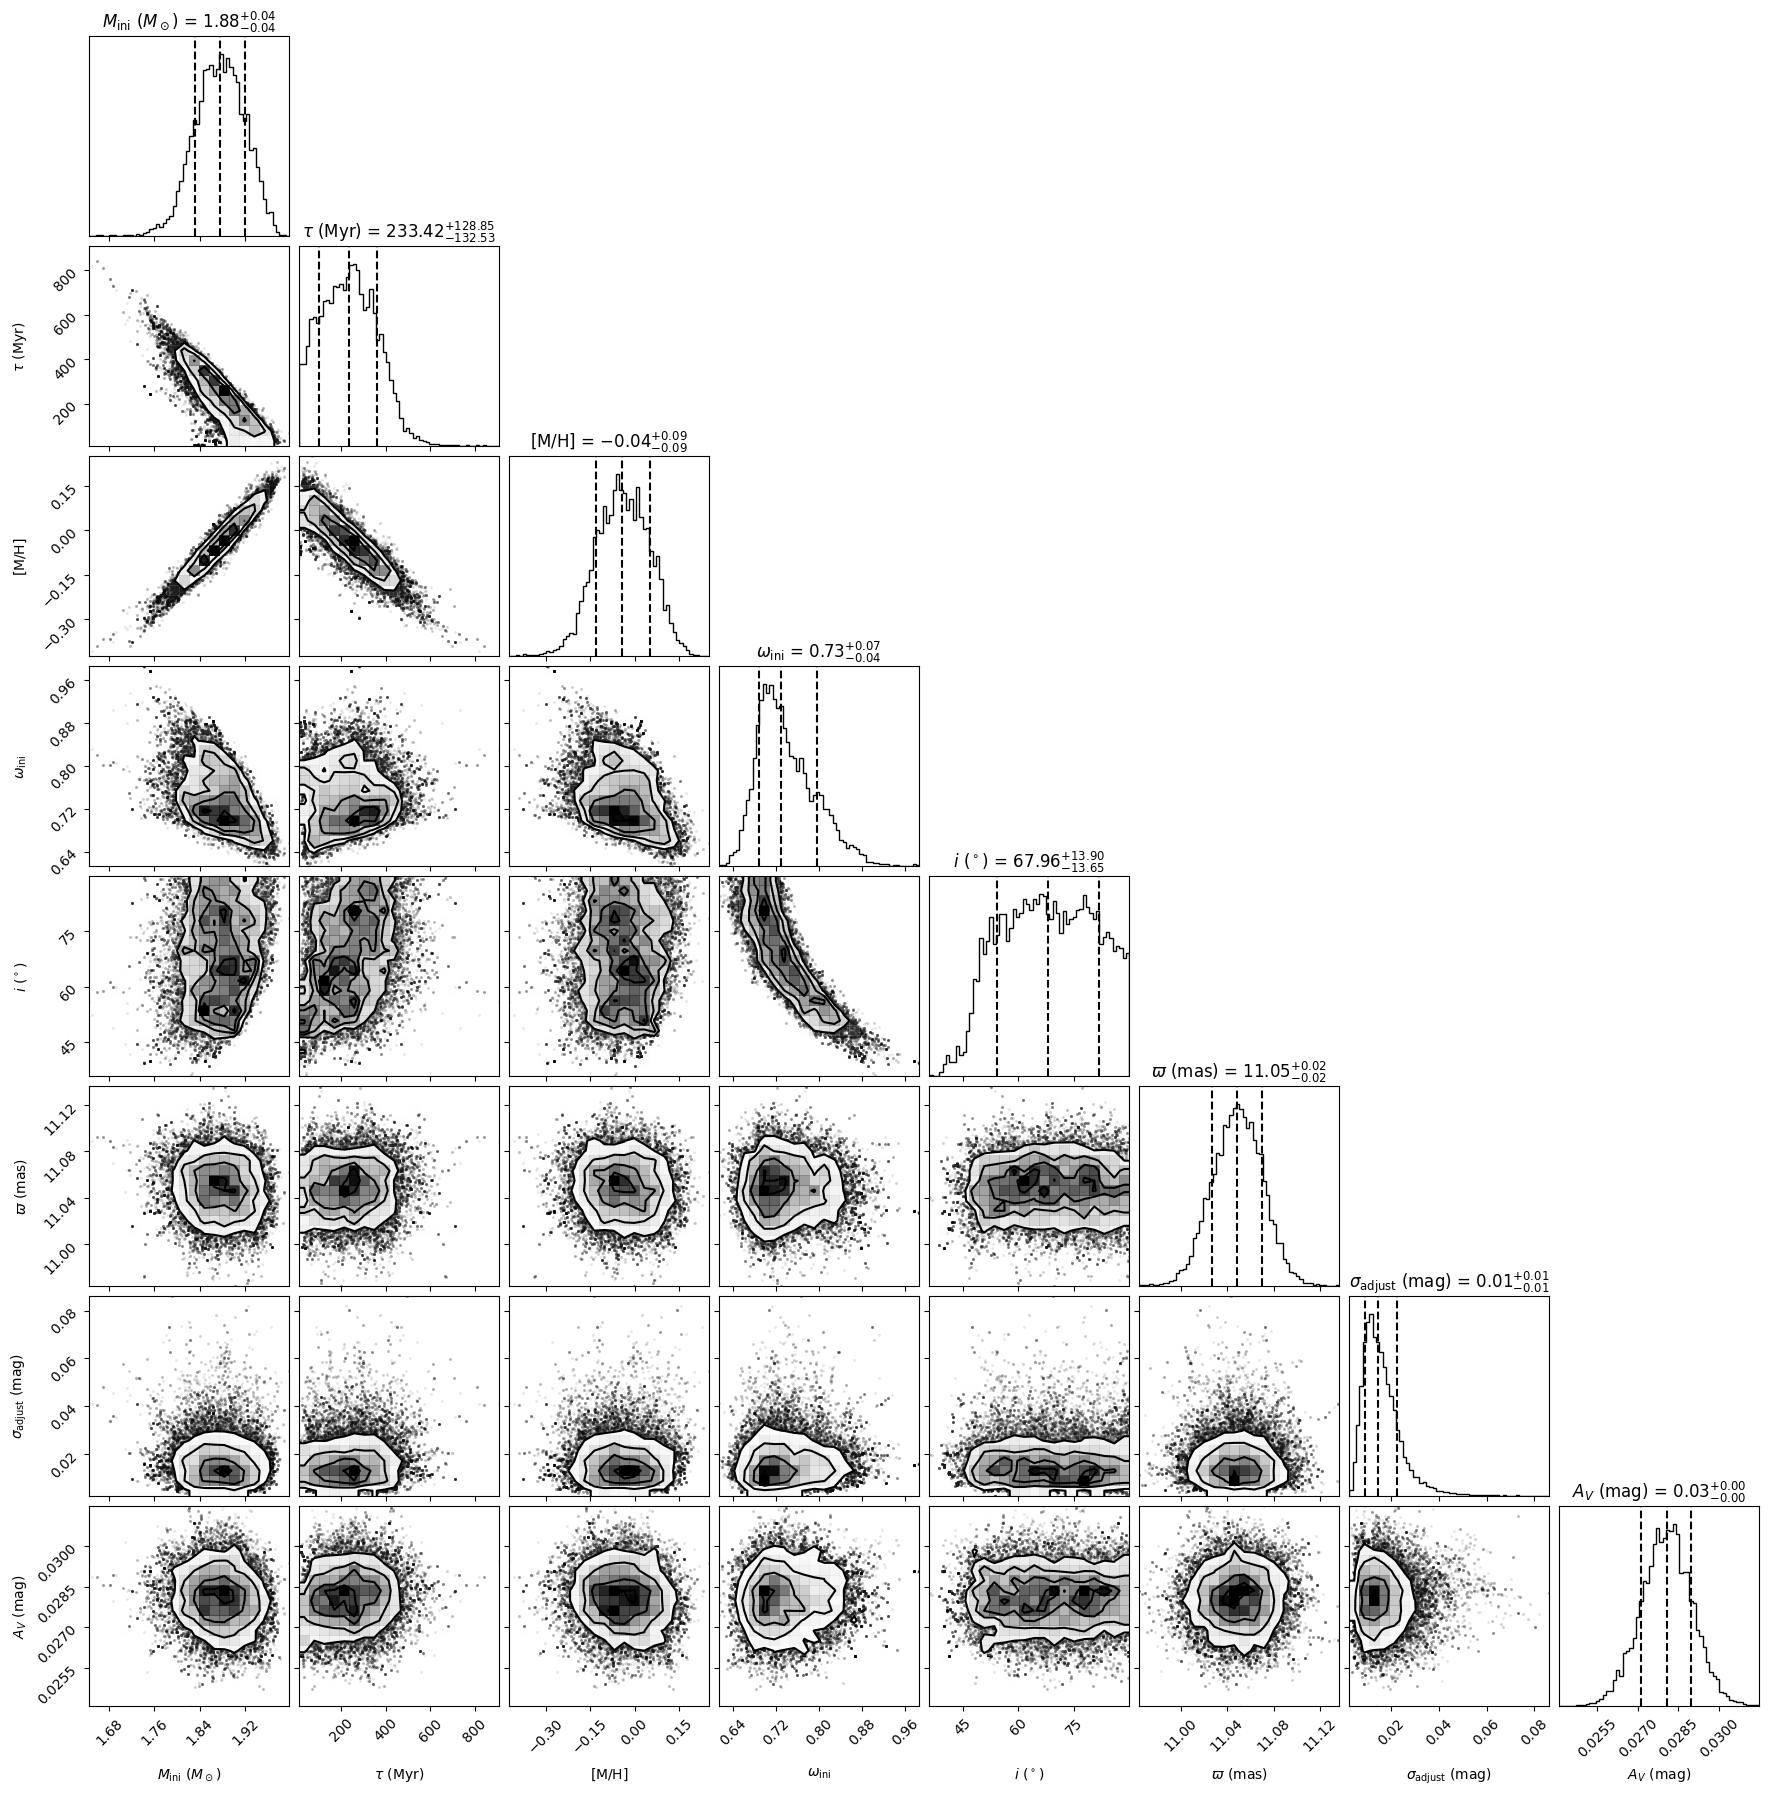

In [69]:
emcee_moves = [
    (emcee.moves.StretchMove(a=2.0),         0.50),
    (emcee.moves.DEMove(gamma0=0.40),        0.20),
    (emcee.moves.DESnookerMove(),            0.15),
    (emcee.moves.KDEMove(),                  0.15),
]
# target.Vrot_prior = None
# target.Vrot_prior = lambda x: 0
mcmc.target = target

sampler_test, rough_mass = mcmc.run_test_sampling(
    nsteps_test=3000,
    emcee_moves = emcee_moves,
    save_samples=False,
    # corner_age_type='log',
    save_path='/Users/ziyinggu/Downloads/emcee_samples',
)

In [ ]:
# max(sampler_test.get_log_prob(flat=True)[:])

samples = sampler_test.get_chain(flat=True)
blobs = sampler_test.get_blobs(flat=True)
probs = sampler_test.get_log_prob(flat=True)

In [ ]:
blobs[-10000]

In [ ]:
from matplotlib import pyplot as plt
import corner


In [ ]:

fig = corner.corner(
    samples[probs>20, :],
    # labels=labels,
    show_titles=True,
    quantiles=[0.16, 0.5, 0.84],
)
plt.show()

In [70]:
# Run sampling!
# Set max time for running and processes for parallel

mcmc.target = target
sampler = mcmc.run_sampling(initial_steps = 10000, # the interval for checking convergence (e.g. 10000, 30000, 60000)
                            max_hours=10, # hours; if reaching max_hours, stop sampling anyway.
                            n_processes=8, # the number of threads used for parallel sampling.
                            emcee_moves = emcee_moves,
                            )

# Play sounds to indicate completion. (For Mac only.)
for _ in range(3):
	os.system("afplay /System/Library/Sounds/Glass.aiff")

🔄 Starting initial sampling...


100%|██████████| 10000/10000 [01:11<00:00, 140.51it/s]


🚀 Standard criteria in use 💪: N/τ > 70, τ_diff < 20%

🔍 Checkpoint @ 10000 samples (elapsed 0h 1m)
  τ₀․₅=263.6, τ₀․₃=196.1, rel_diff=25.6%
  Length ratio (after burn=10τ): 27.94 vs requirement 70
⏱ Adaptive check_interval = 2635 (10×τ_late=2636)


100%|██████████| 2635/2635 [00:18<00:00, 141.01it/s]



🔍 Checkpoint @ 12635 samples (elapsed 0h 1m)
  τ₀․₅=283.5, τ₀․₃=231.9, rel_diff=18.2%
  Length ratio (after burn=10τ): 34.56 vs requirement 70
⏱ Adaptive check_interval = 2835 (10×τ_late=2835)


100%|██████████| 2835/2835 [00:20<00:00, 140.16it/s]


... (7 outputs left out)

100%|██████████| 3232/3232 [00:23<00:00, 136.85it/s]



🔍 Checkpoint @ 28584 samples (elapsed 0h 3m)
  τ₀․₅=327.5, τ₀․₃=299.6, rel_diff=8.5%
  Length ratio (after burn=10τ): 77.28 vs requirement 70
⏱ Adaptive check_interval = 3275 (10×τ_late=3275)


100%|██████████| 3275/3275 [00:24<00:00, 135.10it/s]



🔍 Checkpoint @ 31859 samples (elapsed 0h 3m)
  τ₀․₅=327.8, τ₀․₃=275.0, rel_diff=16.1%
  Length ratio (after burn=10τ): 87.20 vs requirement 70
✅ Converged: τ stable (2×) rel_diff < 0.2, N/τ > 70
Total sampling time: 00:03:51


📏 τ₀․₅=327.8, τ₀․₃=275.0, τ_late=327.8 → burn-in=3277
Your plots and samples will be saved at 
	/Users/ziyinggu/Programming/Projects/belfast-astro/results/HIP_46065_PARSEC_DIRECT_Mini_grid_sigma1_A_V (G-Tomo A_V prior; MH = 0.038 (+0.10, -0.06))
True values: [None, None, None, None, None, None]
Finished saving plots.
Saved folder: /Users/ziyinggu/Programming/Projects/belfast-astro/results/HIP_46065_PARSEC_DIRECT_Mini_grid_sigma1_A_V (G-Tomo A_V prior; MH = 0.038 (+0.10, -0.06))


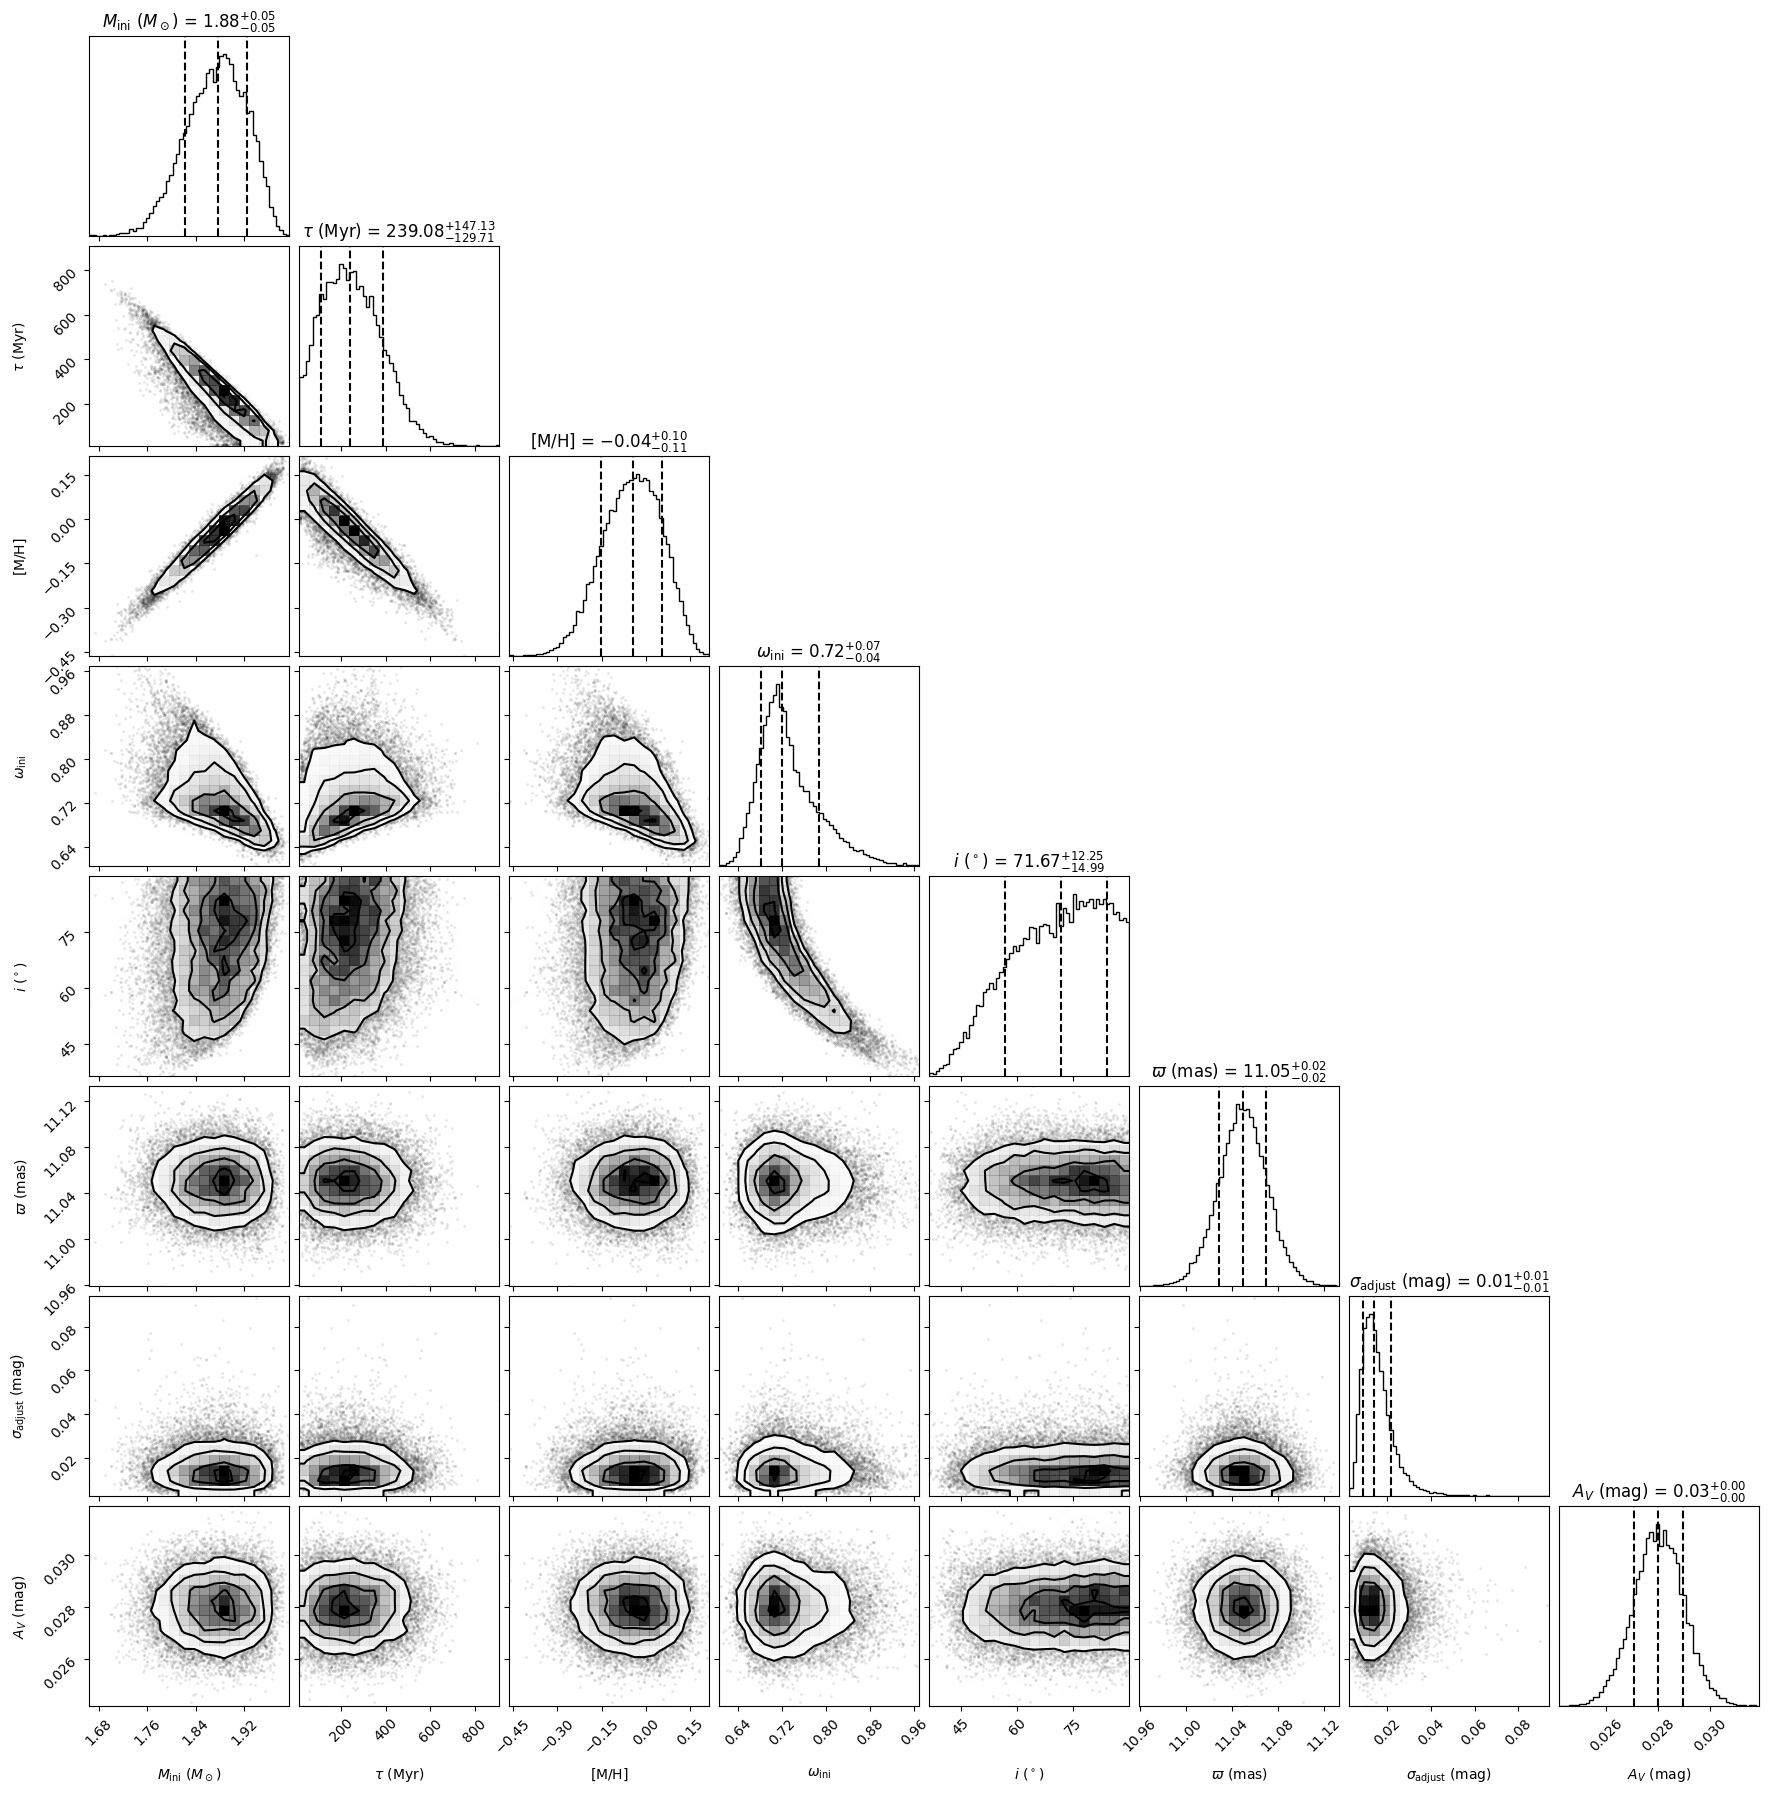

In [77]:
 # Save figures and samples, including the corner plot and trace plots for all walkers.
# The initial 10% of samples are discarded as burn-in.

mcmc.target = target
# mcmc.save_chains_plot(sampler, plot_samples=20000, folder_suffix=f'D = 0.4, G-Tomo A_V prior, MH prior 0.01±0.08', save_samples=True)
# mcmc.save_chains_plot(sampler, plot_samples=20000, folder_suffix=f'G-Tomo A_V prior; MH=-0.02 (-0.14, +0.12)', save_samples=True)
# mcmc.save_chains_plot(sampler, plot_samples=20000, folder_suffix=f'G-Tomo A_V prior', save_samples=True)
# mcmc.save_chains_plot(sampler, plot_samples=20000, folder_suffix=f'non-rotating grids; G-Tomo A_V prior; MH=0.00±0.05', save_samples=True)
# mcmc.save_chains_plot(sampler, plot_samples=20000, folder_suffix=f'G-Tomo A_V prior; MH=0.09±0.05; inc=30±6deg', save_samples=True)
# mcmc.save_chains_plot(sampler, plot_samples=20000, folder_suffix=f'G-Tomo A_V prior; inc=28±6deg', save_samples=True)
mcmc.save_chains_plot(sampler, plot_samples=20000, folder_suffix=f'G-Tomo A_V prior; MH = 0.038 (+0.10, -0.06)', save_samples=True)
# mcmc.save_chains_plot(sampler, plot_samples=20000, folder_suffix=f'G-Tomo A_V prior', save_samples=True)

In [ ]:
s = sampler.get_chain(flat=True)[421160:, :]
p = sampler.get_log_prob(flat=True)[421160:]

In [ ]:
vsini_obs

In [ ]:
samples = sampler.get_chain(flat=True)

In [ ]:
import numpy as np

def mini_to_u(Mini, logAge, MH, omega_ini, interp_bounds, eps=1e-12, clip=False):
    """
    Convert Mini samples to u.

    Parameters
    ----------
    Mini, logAge, MH, omega_ini : array-like
        Must have the same shape.
    interp_bounds : RegularGridInterpolator
        Maps (logAge, MH, omega_ini) -> [Mini_min_used, Mini_max]
    eps : float
        Small threshold for valid width.
    clip : bool
        If True, clip u into [0, 1].

    Returns
    -------
    u : ndarray
    bounds : ndarray
        shape (..., 2), last dim = [Mini_min_used, Mini_max]
    """
    Mini = np.asarray(Mini, dtype=np.float64)
    logAge = np.asarray(logAge, dtype=np.float64)
    MH = np.asarray(MH, dtype=np.float64)
    omega_ini = np.asarray(omega_ini, dtype=np.float64)

    if not (Mini.shape == logAge.shape == MH.shape == omega_ini.shape):
        raise ValueError("Mini, logAge, MH, omega_ini must have the same shape.")

    shape = Mini.shape

    p = np.column_stack([
        logAge.ravel(),
        MH.ravel(),
        omega_ini.ravel()
    ])

    bounds = interp_bounds(p)   # (N, 2)
    Mini_min_used = bounds[:, 0]
    Mini_max = bounds[:, 1]
    width = Mini_max - Mini_min_used

    u = np.full(Mini.size, np.nan, dtype=np.float64)
    valid = np.isfinite(width) & (width > eps)
    u[valid] = (Mini.ravel()[valid] - Mini_min_used[valid]) / width[valid]

    if clip:
        u = np.clip(u, 0.0, 1.0)

    return u.reshape(shape), bounds.reshape(shape + (2,))

In [ ]:
u_samples, bounds = mini_to_u(
    Mini=samples[:,0],
    logAge=samples[:,1],
    MH=samples[:,2],
    omega_ini=samples[:,3],
    interp_bounds=interp_bounds
)

In [ ]:
from matplotlib import pyplot as plt

In [ ]:
u_samples.shape

In [ ]:
plt.figure()
plt.hist(u_samples[500000:], bins=100)
# plt.xlim([0.7, 1.1])

plt.axvline(x=0.99, color='tab:red', linestyle='--', label='u=0.99')
plt.legend()
plt.show()
plt.savefig(f'u distribution of {target_name}.pdf')

In [ ]:
cut_samples= samples[np.where(u_samples<0.99), :][0, :, :]

cut_samples[:, 1] = 10**(cut_samples[:, 1]-6)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import corner

# 假设你的数组叫 samples
# shape = (745066, 8)
# samples = ...

labels = [
    'Mini', 'logAge', 'MH', 'omega_ini',
    ' Inclination', 'parallax', 'sigma_adjust', 'A_V'
]

truths = target.true_values.tolist() + [0, 0]
truths[1] = 10**(truths[1]-6)

fig = corner.corner(
    cut_samples[10000:, :],
    labels=labels,
    show_titles=True,
    title_fmt=".3f",
    quantiles=[0.16, 0.5, 0.84],
    bins=40,
    smooth=1.0,
    plot_datapoints=True,
    truths=truths,
    fill_contours=True,
    levels=(0.393, 0.865, 0.989),  # 1σ, 2σ, 3σ roughly in 2D
)

plt.show()

In [ ]:
import os
import re

folder = '/Users/ziyinggu/Programming/GitHub/belfast-astro/Neural_Network_Model/training_data'

files = os.listdir(folder)

target_files = {}
deviation_files = {}

# 分类
for f in files:
    if "target" in f:
        hip = re.search(r'HIP_\d+', f).group()
        target_files[hip] = f
    elif "linear_age_deviation" in f:
        hip = re.search(r'HIP_\d+', f).group()
        deviation_files[hip] = f

# 配对 + 循环
for hip in target_files:
    if hip in deviation_files:
        target_file = target_files[hip]
        deviation_file = deviation_files[hip]

        print(hip)
        print("target:", target_file)
        print("deviation:", deviation_file)
        print("------")

In [ ]:
a=np.load('/Users/ziyinggu/Downloads/emcee_samples/posterior_HIP_42578_Praesepe_PARS_sigma1_A_V_steps300.npz')

In [ ]:
a

In [ ]:
a['samples'].shape

In [ ]:
sampler_test.get_blobs()['blob'].shape

In [ ]:
raw_blobs = sampler.get_blobs()
blobs = raw_blobs["blob"]

In [ ]:
sampler_test.get_chain().shape

In [ ]:
sampler_test.get_chain(flat=True).shape

In [ ]:
o=sampler_test.get_chain()

In [ ]:
o.reshape(-1, *o.shape[2:]).shape

In [ ]:
np.all(o.reshape(-1, *o.shape[2:]) == sampler_test.get_chain(flat=True))

In [ ]:
sampler.get_chain().shape

In [ ]:
plt.figure()
s = sampler.get_log_prob().flatten()
ss = s[(np.isfinite(s)) & (s>-10)]
plt.hist(ss, bins=100)
plt.show()

In [ ]:
plt.figure(figsize=(12,6))
plt.hist(target.interp_u(sampler_test.get_chain()[:, 0, :5]), bins=1000)
plt.xlim(0.8, 1.2)
plt.show()

In [ ]:
sampler_test.get_chain()[:,0, :5].shape

In [ ]:
target.interp_u([2,8,0,0.5, 0.524])

In [ ]:
mock_A = np.load('/Users/ziyinggu/Programming/Projects/belfast-astro/results/Mock_star_A_with_inc_sigma1_A_V (G-Tomo A_V prior; MH=0.01±0.05; inc=30±6deg)/posterior_Mock_star_A_with_inc_sigma1_A_V (G-Tomo A_V prior; MH=0.01±0.05; inc=30±6deg).npz', allow_pickle=True)

In [ ]:
plt.hist(mock_A['blobs'][mock_A['n_discard']:, :, 8].flatten(), bins = 100)

In [ ]:
mock_A.files

In [ ]:
samples = mock_A['blobs'][mock_A['n_discard']:, :, 8].flatten()

# samples = mock_B['samples'][mock_B['n_discard']:, :, 1].flatten()

# samples = mock_B['samples'][mock_B['n_discard']:, :, 4].flatten()

samples = samples[np.isfinite(samples)]

q16, q50, q84 = np.percentile(samples, [16, 50, 84])

err_minus = q50 - q16
err_plus = q84 - q50

print(f"{q50:.4f} +{err_plus:.4f} -{err_minus:.4f}")

In [ ]:
# samples = mock_B['blobs'][mock_B['n_discard']:, :, 8].flatten()

samples = mock_A['samples'][mock_A['n_discard']:, :, 1].flatten()

# samples = mock_B['samples'][mock_B['n_discard']:, :, 4].flatten()

samples = samples[np.isfinite(samples)]

q16, q50, q84 = np.percentile(samples, [16, 50, 84])

err_minus = q50 - q16
err_plus = q84 - q50

print(f"{q50:.4f} +{err_plus:.4f} -{err_minus:.4f}")

In [ ]:
# samples = mock_B['blobs'][mock_B['n_discard']:, :, 8].flatten()

# samples = mock_B['samples'][mock_B['n_discard']:, :, 1].flatten()

samples = mock_A['samples'][mock_A['n_discard']:, :, 4].flatten()

samples = samples[np.isfinite(samples)]

q16, q50, q84 = np.percentile(samples, [16, 50, 84])

err_minus = q50 - q16
err_plus = q84 - q50

print(f"{q50:.4f} +{err_plus:.4f} -{err_minus:.4f}")

In [ ]:
import pandas as pd

In [ ]:
clusters = ['Hyades', 'Praesepe', 'Pleiades']
df_cluster_list = []
for cluster in clusters:
    df_cluster_i = pd.read_csv(f"./data/clusters/{cluster.lower()}_targets.csv")
    df_cluster_i['Cluster'] = cluster
    cols = ['Cluster'] + [c for c in df_cluster_i.columns if c != 'Cluster']
    df_cluster_i = df_cluster_i[cols]
    df_cluster_list.append(df_cluster_i)

df_cluster = pd.concat(df_cluster_list)

In [ ]:
hip_ids = [
    21670, 23497, 20635, 22044, 20641, 21036, 20261, 18170, 18735,
    42993, 42523, 42164, 43050, 42578, 42766, 42485, 42952,
    17527, 17851, 17776, 17579, 17900, 17892, 17862, 17588,
    17000, 17034, 17692
]

hd_ids = [
    29499, 32301, 27934, 30034, 27946, 28556, 27459, 24357, 25202,
    74656, 67710, 73666, 72846, 73818, 74718, 73785, 74135, 73449,
    73575, 73711, 74589,
    23324, 23862, 23753, 23432, 23923, 23913, 23873, 23441, 23629,
    22578, 22614, 23948, 23632, 23872
]

hip_ids_set = set(hip_ids)
hd_ids_set = set(hd_ids)

hip_col = pd.to_numeric(df_cluster['HIP ID'], errors='coerce').astype('Int64')
hd_col = pd.to_numeric(df_cluster['HD ID'], errors='coerce').astype('Int64')

mask = hip_col.isin(hip_ids_set) | hd_col.isin(hd_ids_set)

df_cluster_filtered = df_cluster.loc[mask].copy()
df_cluster_filtered = df_cluster_filtered.reset_index(drop=True)

In [ ]:
df_cluster_filtered.to_csv(f"./data/clusters/targets_for_sampling.csv", index=False)

In [ ]:
import pandas as pd
pd.read_csv(f"./data/clusters/targets_for_sampling.csv")